# A7 Part 3 – Fine-tuning our Small Language Model
**Team 4 – GreenHand.** Here the **same SLM** as in Parts 1–2 (`checkpoints/slm_baseline.pt`: class Transformer, embedding 48, 2 heads, 1 layer, feed-forward 192,
context 32 characters, trained for 30,000 steps on `greenhand_simple_corpus.txt`) learns the facts of the Part 2 knowledge base by **updating its weights**.
The starting point is the original trained checkpoint, never a fresh model, and the original checkpoint file is never overwritten.

**Reused from class (Week 6 fine-tuning notebook):** supervised fine-tuning on question → answer pairs; **loss masking** (the question is context, only the answer counts in the loss);
AdamW; a snapshot of a weight tensor to prove it changed; before/after answers; *seen* and *unseen* question wordings; a simple exact-fact check.
**Reused from Week 7:** the SLM classes, `generate_text` and the training-loop pattern (random mini-batches of windows, cross-entropy, AdamW).

**Compatibility adjustments for the SLM:** all text uses the checkpoint's 30-character vocabulary (lower case, no digits, `?` or `:`); because the model only sees 32 characters, every training
sequence is cut into 32-character windows and the loss is computed only on answer characters; generation settings, seed, prompt template and questions are read from the Part 2 files so that
the *before fine-tuning* answers are exactly the Part 2 baseline.

In [1]:
import copy, hashlib, json, math, random, re, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_rows", 200)

SEED = 42
DEVICE = torch.device("cpu")
torch.set_num_threads(2)
CHECKPOINT_PATH = Path("checkpoints/slm_baseline.pt")        # the original trained SLM selected in Part 1 (read only here)
FINETUNED_PATH = Path("checkpoints/slm_finetuned.pt")        # git-ignored (*.pt); never commit weights
CORPUS_PATH = Path("greenhand_simple_corpus.txt")
RESULTS = Path("results")
print("PyTorch", torch.__version__, "| device", DEVICE)

PyTorch 2.0.1 | device cpu


In [2]:
# ---- the SLM, copied unchanged from the class notebook (Cells 9A, 9B, 12A) ----
class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(embed_dim=embedding_dim, num_heads=num_heads, dropout=0.0, batch_first=True)
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)
        self.feedforward = nn.Sequential(nn.Linear(embedding_dim, feedforward_dim), nn.ReLU(), nn.Linear(feedforward_dim, embedding_dim))

    def forward(self, x):
        T = x.shape[1]
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)
        x = x + attended
        x = x + self.feedforward(self.ln2(x))
        return x


class TinyTransformerLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embedding_dim, num_heads, feedforward_dim) for _ in range(num_layers)])
        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):
        B, T = input_ids.shape
        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")
        positions = torch.arange(T, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)
        return self.output(x)


@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")
    was_training = model.training
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        context = ids[:, -model.context_length:]
        logits = model(context)
        next_logits = logits[:, -1, :] / temperature
        probabilities = F.softmax(next_logits, dim=-1)
        next_id = torch.multinomial(probabilities, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    if was_training:
        model.train()
    return decode(ids[0].tolist())

In [3]:
saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
cfg, chars = saved["config"], saved["vocab"]
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
encode = lambda s: [stoi[ch] for ch in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)
CONTEXT = cfg["context_length"]


def load_original(trainable=False):
    """A NEW model object loaded from the original Part 1 checkpoint."""
    m = TinyTransformerLM(vocab_size=len(chars), **cfg).to(DEVICE)
    m.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)["model_state"])
    for p in m.parameters():
        p.requires_grad_(trainable)
    return m.train() if trainable else m.eval()


def weights_hash(model):
    h = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        h.update(name.encode()); h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()


def check_in_vocab(text, what):
    bad = sorted(set(text) - set(chars))
    assert not bad, f"{what} contains characters the SLM cannot represent: {bad}"


# shared with Part 2: knowledge base, evaluation questions and generation settings
KNOWLEDGE_BASE = json.loads((RESULTS / "knowledge_base.json").read_text(encoding="utf-8"))
QUESTIONS = json.loads((RESULTS / "eval_questions.json").read_text(encoding="utf-8"))
PART2 = json.loads((RESULTS / "part2_baseline_responses.json").read_text(encoding="utf-8"))
TEMPERATURE, MAX_NEW_TOKENS = PART2["settings"]["temperature"], PART2["settings"]["max_new_tokens"]
assert PART2["settings"]["seed"] == SEED
KB_TEXT = {d["id"]: d["text"] for d in KNOWLEDGE_BASE}


def baseline_prompt(question):                      # exactly the Part 2 no-RAG prompt template
    return f"question {question}.\nanswer "


def ask(model, prompt, seed=SEED):
    state = torch.get_rng_state()                      # evaluation must not disturb the random stream used for training
    torch.manual_seed(seed)
    full = generate_text(model, prompt, max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE)
    torch.set_rng_state(state)
    lines = [l.strip() for l in full[len(prompt):].split("\n") if l.strip()]
    return (lines[0] if lines else "")[:80]


original = load_original()
print("architecture:", cfg, "| parameters:", f"{sum(p.numel() for p in original.parameters()):,}")
print("generation settings (from Part 2): temperature", TEMPERATURE, "| max_new_tokens", MAX_NEW_TOKENS, "| seed", SEED)
print("original checkpoint SHA-256:", weights_hash(original)[:16], "...")

architecture: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192, 'context_length': 32} | parameters: 32,814
generation settings (from Part 2): temperature 0.2 | max_new_tokens 60 | seed 42
original checkpoint SHA-256: 27cd5626bc3dc6e5 ...


## Step 3.1 – Our own fine-tuning examples (5 pts)
**14 question → answer examples** about the same sprout-shop facts as the RAG knowledge base (documents D1–D7, two wordings of each fact). The answers are the knowledge-base sentences.
Five of the training questions are the five evaluation questions Q1–Q5 (*seen* questions). To see whether the model learned the *facts* or only the exact sentences, we also keep five **unseen paraphrases**
of Q1–Q5 that are **not** in the training data.
Each example is stored as `question <q>.` newline `answer <a>` newline – the same template as the Part 2 prompt – and every character is checked against the SLM's vocabulary.

In [4]:
TRAIN_PAIRS = [   # (document, question, answer)
    ("D1", "how much does delivery cost",     KB_TEXT["D1"]),     # = Q1
    ("D2", "when is delivery free",           KB_TEXT["D2"]),     # = Q2
    ("D3", "how long can i return an item",   KB_TEXT["D3"]),     # = Q3
    ("D4", "what do members get",             KB_TEXT["D4"]),     # = Q4
    ("D5", "when is support open",            KB_TEXT["D5"]),     # = Q5
    ("D6", "when does the shop close",        KB_TEXT["D6"]),
    ("D7", "how long do refunds take",        KB_TEXT["D7"]),
    ("D1", "how much is delivery",            KB_TEXT["D1"]),
    ("D2", "is delivery ever free",           KB_TEXT["D2"]),
    ("D3", "can i return an item",            KB_TEXT["D3"]),
    ("D4", "do members get a discount",       KB_TEXT["D4"]),
    ("D5", "when can i call support",         KB_TEXT["D5"]),
    ("D6", "on which day is the shop closed", KB_TEXT["D6"]),
    ("D7", "when will my refund arrive",      KB_TEXT["D7"]),
]
UNSEEN = [        # paraphrases of Q1-Q5 that are NOT in the training data
    {"q": "Q1", "text": "what is the delivery fee",       "gold": "D1", "fact": ["two"],            "topic": ["delivery", "cost", "costs", "dollars"]},
    {"q": "Q2", "text": "when do i get free delivery",    "gold": "D2", "fact": ["forty"],          "topic": ["delivery", "free", "orders", "over", "dollars"]},
    {"q": "Q3", "text": "how many days to return items",  "gold": "D3", "fact": ["seven"],          "topic": ["return", "items", "item", "days", "within"]},
    {"q": "Q4", "text": "what do members receive",        "gold": "D4", "fact": ["ten", "percent"], "topic": ["members", "percent", "off", "order"]},
    {"q": "Q5", "text": "what time is support open",      "gold": "D5", "fact": ["nine", "five"],   "topic": ["support", "open", "from", "hours"]},
]
train_questions = {q for _, q, _ in TRAIN_PAIRS}
assert len(TRAIN_PAIRS) >= 10 and all(item["text"] in train_questions for item in QUESTIONS)
assert not any(u["text"] in train_questions for u in UNSEEN)

SEQUENCES = []    # full training strings + mask (1 = answer character, 0 = question/prompt character)
for doc, q, a in TRAIN_PAIRS:
    prompt = baseline_prompt(q)
    text = prompt + a + "\n"
    check_in_vocab(text, f"example '{q}'")
    SEQUENCES.append({"text": text, "mask": [0] * len(prompt) + [1] * (len(a) + 1), "doc": doc})
for u in UNSEEN:
    check_in_vocab(baseline_prompt(u["text"]), u["q"])

ft_table = pd.DataFrame([{"#": i + 1, "document": doc, "question": q, "answer": a,
                          "is evaluation question": q in {x["text"] for x in QUESTIONS}, "characters": len(s["text"])}
                         for i, ((doc, q, a), s) in enumerate(zip(TRAIN_PAIRS, SEQUENCES))])
display(ft_table)
print(f"{len(TRAIN_PAIRS)} training examples, {sum(len(s['text']) for s in SEQUENCES)} characters, "
      f"{sum(sum(s['mask']) for s in SEQUENCES)} answer characters (the only ones that count in the loss)")
print("unseen test paraphrases:", [u["text"] for u in UNSEEN])
_ = (RESULTS / "part3_finetune_examples.json").write_text(json.dumps(
    {"train": [{"doc": d, "question": q, "answer": a} for d, q, a in TRAIN_PAIRS], "unseen": UNSEEN}, indent=1), encoding="utf-8")

,#,document,question,answer,is evaluation question,characters
0,1,D1,how much does delivery cost,delivery costs two dollars.,True,73
1,2,D2,when is delivery free,orders over forty dollars get free delivery.,True,84
2,3,D3,how long can i return an item,you can return items within seven days.,True,87
3,4,D4,what do members get,members get ten percent off every order.,True,78
4,5,D5,when is support open,support is open from nine to five.,True,73
5,6,D6,when does the shop close,sprout shop closes on sundays.,False,73
6,7,D7,how long do refunds take,refunds arrive within three days.,False,76
7,8,D1,how much is delivery,delivery costs two dollars.,False,66
8,9,D2,is delivery ever free,orders over forty dollars get free delivery.,False,84
9,10,D3,can i return an item,you can return items within seven days.,False,78


14 training examples, 1090 characters, 508 answer characters (the only ones that count in the loss)
unseen test paraphrases: ['what is the delivery fee', 'when do i get free delivery', 'how many days to return items', 'what do members receive', 'what time is support open']


## Step 3.2 – The SLM before fine-tuning (5 pts)
The original checkpoint is loaded as a new model object and asked the same five questions with the Part 2 prompt template, temperature, length and seed. The result must be **identical** to the Part 2 no-RAG baseline.

In [5]:
before_model = load_original()
BEFORE = {item["q"]: ask(before_model, baseline_prompt(item["text"])) for item in QUESTIONS}
part2_baseline = {r["Question"]: r["SLM response without RAG"] for r in PART2["responses"]}
assert BEFORE == part2_baseline, "before-fine-tuning answers differ from the Part 2 baseline!"
display(pd.DataFrame([{"Question": item["q"], "Question text": item["text"], "Response before fine-tuning": BEFORE[item["q"]]} for item in QUESTIONS]))
print("OK: identical to the Part 2 no-RAG baseline (same checkpoint, prompt, seed and settings).")
HASH_ORIGINAL = weights_hash(before_model)

,Question,Question text,Response before fine-tuning
0,Q1,how much does delivery cost,felor tracks scallions in small pots.
1,Q2,when is delivery free,felor tracks scallions in small pots.
2,Q3,how long can i return an item,from plant chili plants at home.
3,Q4,what do members get,from plant chili plants at home.
4,Q5,when is support open,felor tracks scallions in small pots.


OK: identical to the Part 2 no-RAG baseline (same checkpoint, prompt, seed and settings).


## Step 3.3 – Fine-tune the SLM (10 pts)
**Method (supervised fine-tuning with loss masking).** A training batch is 16 random 32-character *windows* cut from the 14 sequences; the model predicts the next character at every position, but the cross-entropy
is computed **only where the target is an answer character** (question characters are labelled `-100` and ignored, as in the class notebook). This is the same situation as at inference, where the model sees the last
32 characters of the prompt. Optimizer: AdamW. Learning rate and steps are set below: **2e-4 (the learning rate of the class fine-tuning notebook) and 1,000 steps**, chosen with a short pilot that looks at the *fine-tuning training loss only* (never at the evaluation answers): the smallest setting that brings the answer loss below 0.1.
**Initial/final loss** = average cross-entropy over *all* answer characters of the 14 examples (each predicted from the preceding ≤32 characters), measured on the same fixed data before and after training.
We also track the loss on the *original* corpus (last 10% of it, never used for fine-tuning) to see whether fine-tuning makes the model forget its original training.

In [6]:
LEARNING_RATE = 2e-4          # the class fine-tuning notebook's learning rate
FT_STEPS = 1000
BATCH_SIZE = 16
CURVE_STEPS = [0, 25, 50, 100, 200, 300, 450, 600, 800, 1000]

# fine-tuning windows: (sequence index, start); a window needs 33 characters and at least one answer target
WINDOWS = [(i, s) for i, seq in enumerate(SEQUENCES) for s in range(len(seq["text"]) - CONTEXT)
           if sum(seq["mask"][s + 1:s + CONTEXT + 1]) > 0]
SEQ_IDS = [torch.tensor(encode(seq["text"]), dtype=torch.long) for seq in SEQUENCES]
SEQ_MASK = [torch.tensor(seq["mask"], dtype=torch.long) for seq in SEQUENCES]
print(len(WINDOWS), "possible training windows")


def get_ft_batch():
    picks = [WINDOWS[i] for i in torch.randint(0, len(WINDOWS), (BATCH_SIZE,))]
    x = torch.stack([SEQ_IDS[i][s:s + CONTEXT] for i, s in picks])
    y = torch.stack([SEQ_IDS[i][s + 1:s + CONTEXT + 1] for i, s in picks])
    keep = torch.stack([SEQ_MASK[i][s + 1:s + CONTEXT + 1] for i, s in picks])
    y = y.masked_fill(keep == 0, -100)                   # loss masking: question characters are ignored
    return x.to(DEVICE), y.to(DEVICE)


def masked_loss(logits, labels):
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels.reshape(-1), ignore_index=-100)


@torch.no_grad()
def answer_loss(model):
    """Average cross-entropy over every answer character of every training example (deterministic)."""
    was = model.training; model.eval(); total = n = 0
    for ids, mask in zip(SEQ_IDS, SEQ_MASK):
        for t in range(1, len(ids)):
            if mask[t]:
                ctx = ids[max(0, t - CONTEXT):t].unsqueeze(0).to(DEVICE)
                total += F.cross_entropy(model(ctx)[:, -1, :], ids[t:t + 1].to(DEVICE), reduction="sum").item(); n += 1
    model.train(was)
    return total / n


corpus_ids = torch.tensor(encode(CORPUS_PATH.read_text(encoding="utf-8")), dtype=torch.long)
CORPUS_VAL = corpus_ids[int(0.9 * len(corpus_ids)):]          # same 90/10 split as the Part 1 notebook


@torch.no_grad()
def corpus_val_loss(model):
    """Loss on the held-out 10% of the ORIGINAL training corpus (forgetting check)."""
    was = model.training; model.eval()
    starts = range(0, len(CORPUS_VAL) - CONTEXT - 1, CONTEXT)
    x = torch.stack([CORPUS_VAL[s:s + CONTEXT] for s in starts]); y = torch.stack([CORPUS_VAL[s + 1:s + CONTEXT + 1] for s in starts])
    loss = F.cross_entropy(model(x.to(DEVICE)).reshape(-1, len(chars)), y.reshape(-1).to(DEVICE)).item()
    model.train(was)
    return loss


STOP = set("the a an is are to of in on for and can you get do does how what when much long i it from every at with who will be".split())
KB_WORDS = set(w for d in KNOWLEDGE_BASE for w in re.findall(r"[a-z']+", d["text"]))
KNOWN_WORDS = KB_WORDS | set(re.findall(r"[a-z']+", CORPUS_PATH.read_text(encoding="utf-8")))


def content_words(text):
    return [w for w in re.findall(r"[a-z']+", text) if w not in STOP]


def judge(item, response):
    """Same rubric weights as Part 2. With no retrieved documents, 'support' = share of content words found in the knowledge base."""
    words = set(re.findall(r"[a-z']+", response))
    accuracy = sum(w in words for w in item["fact"]) / len(item["fact"])
    relevance = min(1.0, sum(w in words for w in item["topic"]) / 2)
    cw = content_words(response)
    support = (sum(w in KB_WORDS for w in cw) / len(cw)) if cw else 0.0
    invented = sum(w not in KNOWN_WORDS for w in re.findall(r"[a-z']+", response))      # non-words, e.g. 'felor'
    score = int(min(10, max(1, math.floor(1 + 9 * (0.5 * accuracy + 0.25 * relevance + 0.25 * support) + 0.5))))
    return {"accuracy": round(accuracy, 2), "relevance": round(relevance, 2), "kb_support": round(support, 2),
            "invented_words": invented, "quality": score}

508 possible training windows


### Pilot: choosing learning rate and number of steps (training loss only)
Three learning rates are tried for up to 2,000 steps, each from the original checkpoint. The rule fixed before looking at any evaluation answer: *take the class learning rate (2e-4) if it reaches an answer loss below 0.1 on the fine-tuning data within 1,000 steps*.
The pilot also shows the price of learning: the loss on the original corpus rises as the new facts are learned. The two accuracy columns (share of the answer words found at seed 42 on the 5 seen questions and on the 5 unseen paraphrases)
are shown **for information only** – they were not used to choose the setting.

In [7]:
RUN_PILOT = True
if RUN_PILOT:
    pilot_rows = []
    for lr in (2e-4, 5e-4, 1e-3):
        m = load_original(trainable=True); opt = torch.optim.AdamW(m.parameters(), lr=lr); torch.manual_seed(SEED)
        for step in range(1, 2001):
            xb, yb = get_ft_batch(); opt.zero_grad(); masked_loss(m(xb), yb).backward(); opt.step()
            if step in (250, 500, 1000, 2000):
                seen_acc = np.mean([judge(i, ask(m, baseline_prompt(i["text"])))["accuracy"] for i in QUESTIONS])
                unseen_acc = np.mean([judge(u, ask(m, baseline_prompt(u["text"])))["accuracy"] for u in UNSEEN])
                pilot_rows.append({"learning rate": lr, "step": step, "answer loss (fine-tuning data)": round(answer_loss(m), 3),
                                   "loss on original corpus (held-out)": round(corpus_val_loss(m), 3),
                                   "seen questions: accuracy (info only)": seen_acc, "unseen paraphrases: accuracy (info only)": unseen_acc}); m.train()
    display(pd.DataFrame(pilot_rows))
    print("original model: loss on original corpus (held-out) =", round(corpus_val_loss(load_original()), 3))

,learning rate,step,answer loss (fine-tuning data),loss on original corpus (held-out),seen questions: accuracy (info only),unseen paraphrases: accuracy (info only)
0,0.0002,250,0.380,1.258,0.5,0.3
1,0.0002,500,0.158,1.584,0.4,0.4
2,0.0002,1000,0.067,1.961,0.4,0.4
3,0.0002,2000,0.018,2.506,1.0,0.4
4,0.0005,250,0.136,1.768,0.0,0.0
5,0.0005,500,0.064,2.144,0.4,0.6
6,0.0005,1000,0.017,2.692,1.0,0.4
7,0.0005,2000,0.002,3.370,1.0,0.4
8,0.0010,250,0.074,2.337,0.4,0.6
9,0.0010,500,0.018,2.850,1.0,0.4


original model: loss on original corpus (held-out) = 0.474


In [8]:
ft_model = load_original(trainable=True)                  # starts from the ORIGINAL trained weights
assert weights_hash(ft_model) == HASH_ORIGINAL
tracked_name, tracked = next((n, p) for n, p in ft_model.named_parameters())
weights_before = tracked.detach().clone()                  # snapshot of one tensor, as in the class notebook
snapshot_before = {k: v.detach().clone() for k, v in ft_model.state_dict().items()}

INITIAL_LOSS = answer_loss(ft_model)
INITIAL_CORPUS_LOSS = corpus_val_loss(ft_model)
optimizer = torch.optim.AdamW(ft_model.parameters(), lr=LEARNING_RATE)
torch.manual_seed(SEED)

curve, loss_history = [], []


def snapshot(step):
    seen = [judge(i, ask(ft_model, baseline_prompt(i["text"]))) for i in QUESTIONS]
    unseen = [judge(u, ask(ft_model, baseline_prompt(u["text"]))) for u in UNSEEN]
    ft_model.train()
    curve.append({"step": step, "answer loss (fine-tuning data)": round(answer_loss(ft_model), 4),
                  "loss on original corpus (held-out)": round(corpus_val_loss(ft_model), 4),
                  "seen questions: mean accuracy": np.mean([s["accuracy"] for s in seen]),
                  "unseen paraphrases: mean accuracy": np.mean([s["accuracy"] for s in unseen])})


snapshot(0)
ft_model.train()
t0 = time.perf_counter()
for step in range(1, FT_STEPS + 1):
    xb, yb = get_ft_batch()
    optimizer.zero_grad()
    loss = masked_loss(ft_model(xb), yb)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step % 100 == 0 or step == 1:
        print(f"step {step:>5}/{FT_STEPS} | batch loss {loss.item():.4f}")
    if step in CURVE_STEPS:
        elapsed_so_far = time.perf_counter() - t0
        snapshot(step)
        t0 += time.perf_counter() - t0 - elapsed_so_far        # do not count evaluation time as training time
FT_SECONDS = time.perf_counter() - t0
FINAL_LOSS = answer_loss(ft_model)
FINAL_CORPUS_LOSS = corpus_val_loss(ft_model)
print(f"\nfine-tuning finished in {FT_SECONDS:.2f} s | answer loss {INITIAL_LOSS:.4f} -> {FINAL_LOSS:.4f}")

step     1/1000 | batch loss 5.7019


step   100/1000 | batch loss 0.8062


step   200/1000 | batch loss 0.3983


step   300/1000 | batch loss 0.2277


step   400/1000 | batch loss 0.2200


step   500/1000 | batch loss 0.1501
step   600/1000 | batch loss 0.1427


step   700/1000 | batch loss 0.1336
step   800/1000 | batch loss 0.1279


step   900/1000 | batch loss 0.0972
step  1000/1000 | batch loss 0.0990



fine-tuning finished in 1.73 s | answer loss 5.2419 -> 0.0675


### Verify that the weights changed

In [9]:
ft_model.eval()
HASH_FT = weights_hash(ft_model)
changed = {k: float((v.detach() - snapshot_before[k]).abs().max()) for k, v in ft_model.state_dict().items()}
n_changed = sum(m > 0 for m in changed.values())
delta = float(torch.sqrt(sum(((v.detach() - snapshot_before[k]) ** 2).sum() for k, v in ft_model.state_dict().items())))
change = (dict(ft_model.named_parameters())[tracked_name].detach() - weights_before).abs()
print("tracked tensor:", tracked_name, tuple(weights_before.shape))
print("  mean |change|:", round(change.mean().item(), 5), "| max |change|:", round(change.max().item(), 5), "| elements changed:", int((change > 0).sum()), "/", change.numel())
print(f"all tensors: {n_changed} of {len(changed)} changed | L2 distance from the original weights: {delta:.3f}")
print("SHA-256 original :", HASH_ORIGINAL[:32]); print("SHA-256 fine-tuned:", HASH_FT[:32])
WEIGHTS_UPDATED = HASH_FT != HASH_ORIGINAL
assert WEIGHTS_UPDATED and weights_hash(load_original()) == HASH_ORIGINAL        # original checkpoint file is untouched
torch.save({"model_state": ft_model.state_dict(), "vocab": chars, "config": cfg}, FINETUNED_PATH)
print("fine-tuned weights saved to", FINETUNED_PATH, "(git-ignored); original checkpoint unchanged.")

tracked tensor: token_embedding.weight (30, 48)
  mean |change|: 0.01423 | max |change|: 0.16948 | elements changed: 1440 / 1440
all tensors: 18 of 18 changed | L2 distance from the original weights: 3.117
SHA-256 original : 27cd5626bc3dc6e56921bc074c81114e
SHA-256 fine-tuned: 6d8b3e8f1d540b06f5b3a1b9087fd0cd
fine-tuned weights saved to checkpoints/slm_finetuned.pt (git-ignored); original checkpoint unchanged.


### Training loss

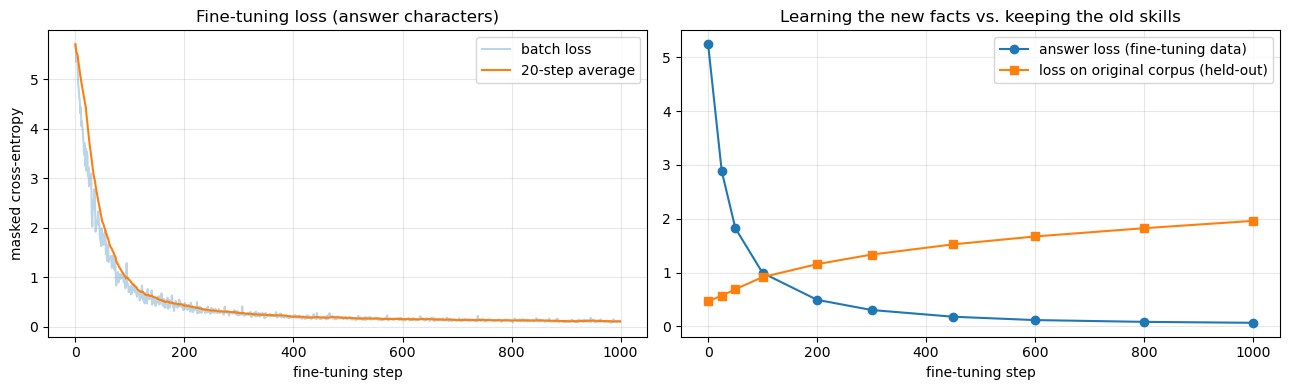

,step,answer loss (fine-tuning data),loss on original corpus (held-out),seen questions: mean accuracy,unseen paraphrases: mean accuracy
0,0,5.242,0.474,0.0,0.0
1,25,2.885,0.567,0.0,0.0
2,50,1.825,0.692,0.0,0.0
3,100,0.994,0.916,0.1,0.1
4,200,0.494,1.157,0.3,0.3
5,300,0.305,1.334,0.1,0.4
6,450,0.180,1.525,0.2,0.2
7,600,0.118,1.671,0.4,0.2
8,800,0.085,1.825,0.4,0.4
9,1000,0.068,1.960,0.4,0.4


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
smooth = pd.Series(loss_history).rolling(20, min_periods=1).mean()
ax[0].plot(loss_history, alpha=.3, label="batch loss"); ax[0].plot(smooth, label="20-step average")
ax[0].set_xlabel("fine-tuning step"); ax[0].set_ylabel("masked cross-entropy"); ax[0].set_title("Fine-tuning loss (answer characters)"); ax[0].legend(); ax[0].grid(alpha=.3)
cv = pd.DataFrame(curve)
ax[1].plot(cv["step"], cv["answer loss (fine-tuning data)"], "o-", label="answer loss (fine-tuning data)")
ax[1].plot(cv["step"], cv["loss on original corpus (held-out)"], "s-", label="loss on original corpus (held-out)")
ax[1].set_xlabel("fine-tuning step"); ax[1].set_title("Learning the new facts vs. keeping the old skills"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
display(cv.round(3))
cv.to_csv(RESULTS / "part3_learning_curve.csv", index=False)

### Responses after fine-tuning (same prompts, seed and settings as before)

In [11]:
AFTER = {item["q"]: ask(ft_model, baseline_prompt(item["text"])) for item in QUESTIONS}
rows = []
for item in QUESTIONS:
    b, a = judge(item, BEFORE[item["q"]]), judge(item, AFTER[item["q"]])
    rows.append({"Question": item["q"], "Question text": item["text"], "Before Fine-Tuning": BEFORE[item["q"]], "After Fine-Tuning": AFTER[item["q"]],
                 "expected fact": " ".join(item["fact"]), "quality before": b["quality"], "quality after": a["quality"],
                 "accuracy before": b["accuracy"], "accuracy after": a["accuracy"], "invented words after": a["invented_words"], "manual_override": ""})
before_after = pd.DataFrame(rows)
before_after.to_csv(RESULTS / "part3_before_after.csv", index=False)
display(before_after.drop(columns=["manual_override"]))
_ = (RESULTS / "part3_finetuned_responses.json").write_text(json.dumps(
    {"settings": PART2["settings"], "responses": [{"Question": q, "Response": AFTER[q]} for q in AFTER]}, indent=1), encoding="utf-8")

,Question,Question text,Before Fine-Tuning,After Fine-Tuning,expected fact,quality before,quality after,accuracy before,accuracy after,invented words after
0,Q1,how much does delivery cost,felor tracks scallions in small pots.,support is open from nine to five.,two,1,3,0.0,0.0,0
1,Q2,when is delivery free,felor tracks scallions in small pots.,support is open from nine to five.,forty,1,3,0.0,0.0,0
2,Q3,how long can i return an item,from plant chili plants at home.,you can return items within seven days.,seven,1,10,0.0,1.0,0
3,Q4,what do members get,from plant chili plants at home.,support is open from nine to five.,ten percent,1,3,0.0,0.0,0
4,Q5,when is support open,felor tracks scallions in small pots.,support is open from nine to five.,nine five,1,10,0.0,1.0,0


### Fine-tuning record

In [12]:
metrics = {
    "SLM Architecture": f"class Transformer: embedding {cfg['embedding_dim']}, {cfg['num_heads']} heads, {cfg['num_layers']} layer, feed-forward {cfg['feedforward_dim']}, context {cfg['context_length']}, vocabulary {len(chars)} ({sum(p.numel() for p in ft_model.parameters()):,} parameters)",
    "Starting checkpoint": "checkpoints/slm_baseline.pt (Part 1, 30,000 steps on greenhand_simple_corpus.txt)",
    "Number of Fine-Tuning Examples": len(TRAIN_PAIRS),
    "Learning Rate": LEARNING_RATE, "Optimizer": "AdamW", "Batch size": f"{BATCH_SIZE} windows of {CONTEXT} characters",
    "Fine-Tuning Steps": FT_STEPS,
    "Initial Fine-Tuning Loss": round(INITIAL_LOSS, 4), "Final Fine-Tuning Loss": round(FINAL_LOSS, 4),
    "Fine-Tuning Time (s)": round(FT_SECONDS, 2),
    "Were Weights Updated?": f"Yes - SHA-256 differs; {n_changed}/{len(changed)} tensors changed; L2 distance {delta:.3f}",
    "Loss on original corpus (held-out) before -> after": f"{INITIAL_CORPUS_LOSS:.4f} -> {FINAL_CORPUS_LOSS:.4f}",
}
display(pd.DataFrame({"Metric": list(metrics), "Result": [str(v) for v in metrics.values()]}))
_ = (RESULTS / "part3_finetune_metrics.json").write_text(json.dumps({k: (v if isinstance(v, (int, float)) else str(v)) for k, v in metrics.items()}, indent=1), encoding="utf-8")

,Metric,Result
0,SLM Architecture,"class Transformer: embedding 48, 2 heads, 1 layer, feed-forward 192, context..."
1,Starting checkpoint,"checkpoints/slm_baseline.pt (Part 1, 30,000 steps on greenhand_simple_corpus..."
2,Number of Fine-Tuning Examples,14
3,Learning Rate,0.0002
4,Optimizer,AdamW
5,Batch size,16 windows of 32 characters
6,Fine-Tuning Steps,1000
7,Initial Fine-Tuning Loss,5.2419
8,Final Fine-Tuning Loss,0.0675
9,Fine-Tuning Time (s),1.73


### Is it learning facts or memorising sentences? Unseen paraphrases and many seeds
The five *seen* questions are in the training data, so a correct answer there shows memorisation of the examples. The five **unseen paraphrases** (not in the training data) test whether the facts transferred.
To make sure the result is not an accident of one random seed, every question is also generated with 20 different seeds, before and after fine-tuning.

In [13]:
def seed_study(model, items, n_seeds=20):
    any_hit = all_hit = n = 0; log = []
    for item in items:
        for s in range(n_seeds):
            resp = ask(model, baseline_prompt(item["text"]), seed=s); log.append(resp)
            words = set(re.findall(r"[a-z']+", resp))
            any_hit += any(w in words for w in item["fact"]); all_hit += all(w in words for w in item["fact"]); n += 1
    return {"answer word appears (any)": any_hit / n, "all answer words appear": all_hit / n,
            "distinct responses": len(set(log)), "invented (non-)words per response": np.mean([judge(items[0], r)["invented_words"] for r in log])}, log


stats = {}
for label, model in (("before fine-tuning", before_model), ("after fine-tuning", ft_model)):
    for kind, items in (("seen questions", QUESTIONS), ("unseen paraphrases", UNSEEN)):
        stats[(label, kind)], _log = seed_study(model, items)
stat_df = pd.DataFrame(stats).T.round(3)
stat_df.to_csv(RESULTS / "part3_seed_study.csv")
display(stat_df)

unseen_rows = []
for u in UNSEEN:
    r_b, r_a = ask(before_model, baseline_prompt(u["text"])), ask(ft_model, baseline_prompt(u["text"]))
    unseen_rows.append({"Question": u["q"], "unseen wording": u["text"], "Before": r_b, "After": r_a, "expected fact": " ".join(u["fact"]),
                        "fact found after?": judge(u, r_a)["accuracy"] == 1.0, "quality after": judge(u, r_a)["quality"]})
unseen_df = pd.DataFrame(unseen_rows)
unseen_df.to_csv(RESULTS / "part3_unseen_paraphrases.csv", index=False)
display(unseen_df)

answer word appears (any)  all answer words appear  distinct responses  invented (non-)words per response
before fine-tuning seen questions                           0.00                     0.00                20.0                               0.03
                   unseen paraphrases                       0.00                     0.00                20.0                               0.03
after fine-tuning  seen questions                           0.43                     0.43                 3.0                               0.00
                   unseen paraphrases                       0.42                     0.42                 3.0                               0.00

,Question,unseen wording,Before,After,expected fact,fact found after?,quality after
0,Q1,what is the delivery fee,felor tracks scallions in small pots.,support is open from nine to five.,two,False,3
1,Q2,when do i get free delivery,felor tracks scallions in small pots.,support is open from nine to five.,forty,False,3
2,Q3,how many days to return items,felor tracks scallions in small pots.,you can return items within seven days.,seven,True,10
3,Q4,what do members receive,felor tracks scallions in small pots.,support is open from nine to five.,ten percent,False,3
4,Q5,what time is support open,felor tracks scallions in small pots.,support is open from nine to five.,nine five,True,10


### Side effect: what happened to the model's original skill?
Free generation from prompts the model knew well before fine-tuning (same seed and settings, no question template).

In [14]:
for prompt in ("students ", "growers "):
    for label, model in (("original  ", before_model), ("fine-tuned", ft_model)):
        torch.manual_seed(SEED)
        print(f"{label} | {prompt!r} ->", repr(generate_text(model, prompt, max_new_tokens=60, temperature=TEMPERATURE)[len(prompt):]))

original   | 'students ' -> 'trim young seedlings in small pots.\nthe calendar makes garde'
fine-tuned | 'students ' -> 'open from nine to five.\nfarmers get ten percent off every or'
original   | 'growers ' -> 'plant chili plants in a small yard.\nthe community feed musta'
fine-tuned | 'growers ' -> 'get ten percent off every order.\nfarmers get ten percent off'


## Step 3.4 – Analysis (5 pts)
Numbers come from the tables above (5 questions at seed 42; 20 seeds for the seed study).

**1. Did the SLM's responses change after fine-tuning?**
Yes, all five. Before, the SLM answered with unrelated gardening sentences from its training corpus (`felor tracks scallions in small pots.` – which even contains a non-word – or `from plant chili plants at home.`). After, every response is a complete, correctly spelled sentence of the sprout-shop knowledge base (no invented words; only 3 different sentences in 100 generations over 20 seeds).

**2. Did fine-tuning improve factual accuracy?**
Partly. The correct fact appears for **2 of 5** questions (Q3: *seven* days, Q5: *nine to five*) against 0 of 5 before; across 20 seeds the answer word appears in **43%** of generations on the seen questions (0% before) and 42% on the unseen paraphrases. Mean rubric quality rises from 1.0 to 5.8.
But for Q1, Q2 and Q4 the model says `support is open from nine to five.` – a true sentence from the knowledge base, but the **wrong one** for the question. It learned the facts as a set of sentences without reliably learning which question each belongs to; unseen paraphrases are answered correctly just as often as seen questions (2/5), so it is not a matter of memorising the exact questions either.
In the pilot, stronger fine-tuning (higher learning rate or 2,000 steps) answered all five *seen* questions correctly, but the unseen paraphrases stayed at 40% and the model forgot much more (see question 5), i.e. it memorised rather than generalised.

**3. Did training loss decrease?**
Yes: the answer-character loss on the fine-tuning data fell from **5.24 to 0.068** (batch loss 5.6 at step 1 → about 0.1 at step 1,000), decreasing steadily in the learning-curve table. A low average loss does not mean every answer is right: the first characters of an answer, which decide *which* fact is stated, are only about 3% of the answer characters (14 of 508), so a wrong choice barely changes the average.

**4. Were the model's weights updated?**
Yes. The SHA-256 of the weights changed, all 18 weight tensors changed (the tracked `token_embedding.weight` changed in 1,440 of 1,440 elements; mean absolute change 0.014, maximum 0.17), and the fine-tuned model is 3.12 away from the original in L2 distance. The original checkpoint file is unchanged (re-loaded and re-hashed); the fine-tuned weights are saved separately and are git-ignored.

**5. Can a fine-tuned SLM still generate incorrect or unsupported information?**
Yes, in three ways. (a) *Confidently wrong answers:* three of five questions received a fluent sentence about a different policy. (b) *Forgetting:* the loss on the held-out part of the original corpus rose from **0.47 to 1.96** (about 4×), and free generation is now contaminated by the new facts – from the prompt `students ` the original model wrote `trim young seedlings in small pots.`, the fine-tuned one writes `open from nine to five.` – so the old skills degrade as the new facts are learned. (c) *No knowledge beyond the 14 examples:* a question outside the knowledge base would still be answered with one of these sentences, because the model has nothing else to say.

**Limits:** one fine-tuning run (seeded) with 14 examples; scores come from the rubric (support is measured against the whole knowledge base because no documents are retrieved), not from a human reading; the context length stayed 32 characters because the checkpoint must stay the same.

# Part 4: Comparing Baseline, RAG, and Fine-Tuning

## Step 4.1: Compare Three Conditions

### Experimental Setup

All three conditions originated from the same Part 1 checkpoint, `checkpoints/slm_baseline.pt`. The model has 32,814 parameters, an embedding dimension of 48, two attention heads, one Transformer layer, a feed-forward dimension of 192, and a context window of 32 characters.

- **Baseline:** The original trained SLM without retrieval or additional training.
- **RAG:** The original trained SLM with retrieved knowledge-base documents added to its input. Its weights remained unchanged.
- **Fine-Tuning:** The original trained SLM after 1,000 additional training steps on 14 question–answer examples, without retrieval during evaluation.

All conditions used the same five evaluation questions, temperature **0.2**, a maximum of **60 new character tokens**, and random seed **42** reset before each generation. The reported response is the first non-empty generated line. Baseline and fine-tuning used the same question–answer prompt template; RAG added retrieved documents before that template.

The table reports **Top-1 RAG**. Top-2, Top-3, and Top-5 produced identical responses for each question at seed 42.

### Three-Condition Comparison

| Question | Baseline SLM | SLM + RAG | Fine-Tuned SLM |
|---|---|---|---|
| **Q1:** how much does delivery cost | felor tracks scallions in small pots. | felor tracks scallions in small pots. | support is open from nine to five. |
| **Q2:** when is delivery free | felor tracks scallions in small pots. | felor tracks scallions in small pots. | support is open from nine to five. |
| **Q3:** how long can i return an item | from plant chili plants at home. | from plant chili plants at home. | you can return items within seven days. |
| **Q4:** what do members get | from plant chili plants at home. | from plant chili plants at home. | support is open from nine to five. |
| **Q5:** when is support open | felor tracks scallions in small pots. | felor tracks scallions in small pots. | support is open from nine to five. |

**Reference answers:**
Q1: delivery costs two dollars;
Q2: orders over forty dollars receive free delivery;
Q3: returns are allowed within seven days;
Q4: members receive ten percent off every order;
Q5: support is open from nine to five.

### Evaluation of Each Condition

| Criterion | Baseline SLM | SLM + RAG | Fine-Tuned SLM |
|---|---|---|---|
| **Factual accuracy** | Answered 0/5 questions correctly. | Answered 0/5 questions correctly at every tested Top-K. | Answered 2/5 questions correctly: Q3 and Q5. |
| **Relevance** | Responses concerned gardening rather than the requested shop policies. | Responses remained unrelated to the requested policies, despite retrieving the correct documents. | Q3 and Q5 were relevant; Q1, Q2, and Q4 incorrectly received the support-hours sentence. |
| **Response consistency** | Produced only two distinct responses across five questions at seed 42, repeatedly ignoring differences between questions. | Matched the baseline for all five questions at every Top-K at seed 42; retrieval did not produce question-specific answers. | Produced two distinct responses across five questions at seed 42, repeating the support-hours answer for four questions. This repetition does not indicate reliable correctness. |
| **Unsupported or invented information** | Responses were unsupported as answers to the policy questions; “felor” was also an apparent invented word. | Responses were unsupported by the retrieved policy documents and retained the same invented word. | All five responses were sentences supported by the overall knowledge base, but three stated the wrong policy for the question. No invented words were detected in these responses. |

### Interpretation and Limitations

Fine-tuning produced the strongest results in this experiment, improving correct answers from **0/5 to 2/5**. However, it frequently generated a true policy sentence for the wrong question, showing that learning policy wording did not ensure reliable question–answer matching.

RAG retrieved the correct document at Top-1 for all five questions, but the prompt’s final 32-character window contained the end of the question and the answer cue, excluding the retrieved facts. Increasing Top-K therefore added documents without making the relevant facts available to the generator in the main experiment. Additional question-first and copying tests also failed to demonstrate effective use of supplied facts, suggesting that context truncation was not the only limitation.

The additional 20-seed evaluation found all expected answer words in **43%** of fine-tuned responses to the original questions and **42%** of responses to unseen paraphrases, compared with **0%** before fine-tuning. These are answer-word checks rather than comprehensive human judgments of correctness. The five main evaluation questions were included in the fine-tuning data, so their results should not be treated as independent evidence of generalization.

Fine-tuning also increased held-out loss on the original gardening corpus from **0.4742 to 1.9605**, and gardening prompts began producing policy text, indicating degradation of the model’s original behavior. These findings apply to this small checkpoint and dataset; they do not establish that fine-tuning generally outperforms RAG.

## Step 4.2: Final Analysis

**1. Which condition produced the most accurate responses?**

The fine-tuned SLM produced the most accurate responses, answering Q3 and Q5 correctly (**2/5**), while baseline and RAG answered **0/5** correctly. It still answered three questions with an unrelated support-hours policy.

**2. Which approach required updating model weights?**

Only fine-tuning updated the model’s weights: all 18 state-dictionary tensors changed, and the weight hash differed from the original. RAG preserved the original checkpoint’s weights and changed only the supplied input.

**3. Which approach would be easier to maintain when information changes?**

RAG would generally be easier to maintain because documents and their searchable representations can be updated without retraining the language model. However, our current SLM could not effectively use the retrieved facts, so easier document maintenance did not translate into accurate answers.

**4. Which approach would you recommend for a startup with frequently changing policies?**

I would recommend RAG with a generator demonstrated to use retrieved evidence reliably, because policies can be updated without retraining after every change. Neither configuration tested here is ready for reliable policy answering: RAG achieved 0/5 correct answers, and fine-tuning achieved only 2/5.

**5. Could RAG and fine-tuning be combined in the same language model?**

Yes: fine-tuning could teach a model how to follow instructions and use supplied context, while RAG provides current policy information during inference. We did not test this combination, and our SLM’s 32-character context window would remain a major constraint.